# Autoencoder Architecture

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import zipfile
import os

# Define the path to the zip file and the extraction directory
zip_file_path = '/content/drive/MyDrive/UCSD_Anomaly_Dataset.zip'
extract_path = '/content/UCSD_Anomaly'

# Extract the zip file
with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction completed.")

Extraction completed.


In [1]:
import os
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.metrics import roc_auc_score, roc_curve
from tqdm import tqdm

In [2]:
# Define the dataset class
class UCSDDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.frames = []
        self.load_frames()

    def load_frames(self):
        for folder in os.listdir(self.root_dir):
            folder_path = os.path.join(self.root_dir, folder)
            if os.path.isdir(folder_path) and (folder.startswith('Train') or folder.startswith('Test')):
                for frame_name in os.listdir(folder_path):
                    if frame_name.endswith('.tif'):
                        self.frames.append(os.path.join(folder_path, frame_name))
        print(f"Loaded {len(self.frames)} frames from {self.root_dir}")

    def __len__(self):
        return len(self.frames)

    def __getitem__(self, idx):
        frame_path = self.frames[idx]
        try:
            image = Image.open(frame_path).convert("RGB")
        except (OSError, IOError) as e:
            print(f"Error loading image {frame_path}: {e}")
            return self.__getitem__((idx + 1) % len(self.frames))
        if self.transform:
            image = self.transform(image)
        return image

# Transformations for the images
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomResizedCrop((128, 128), scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    transforms.Lambda(lambda x: x + 0.01 * torch.randn_like(x))  # Adding Gaussian noise
])

# Create datasets and dataloaders
train_dataset = UCSDDataset('/content/UCSD_Anomaly/UCSD_Anomaly_Dataset/UCSD_Anomaly_Dataset.v1p2/UCSDped1/Train', transform=transform)
test_dataset = UCSDDataset('/content/UCSD_Anomaly/UCSD_Anomaly_Dataset/UCSD_Anomaly_Dataset.v1p2/UCSDped1/Test', transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0, pin_memory=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=0, pin_memory=False)

# Check if data loading works correctly
print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of testing samples: {len(test_dataset)}")

Loaded 6800 frames from /content/UCSD_Anomaly/UCSD_Anomaly_Dataset/UCSD_Anomaly_Dataset.v1p2/UCSDped1/Train
Loaded 7200 frames from /content/UCSD_Anomaly/UCSD_Anomaly_Dataset/UCSD_Anomaly_Dataset.v1p2/UCSDped1/Test
Number of training samples: 6800
Number of testing samples: 7200


In [3]:
class SEBlock(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super(SEBlock, self).__init__()
        self.fc1 = nn.Linear(in_channels, in_channels // reduction, bias=False)
        self.fc2 = nn.Linear(in_channels // reduction, in_channels, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        b, c, _, _ = x.size()
        y = torch.mean(x, (2, 3))
        y = self.fc1(y)
        y = self.fc2(y)
        y = self.sigmoid(y).view(b, c, 1, 1)
        return x * y

In [4]:
import torch.nn.functional as F

class UNetSE(nn.Module):
    def __init__(self, in_channels=3, out_channels=3, init_features=32):
        super(UNetSE, self).__init__()
        features = init_features

        self.encoder1 = UNetSE._block(in_channels, features, name="enc1")
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoder2 = UNetSE._block(features, features * 2, name="enc2")
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoder3 = UNetSE._block(features * 2, features * 4, name="enc3")
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.encoder4 = UNetSE._block(features * 4, features * 8, name="enc4")
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.bottleneck = UNetSE._block(features * 8, features * 16, name="bottleneck")
        
        self.se1 = SEBlock(features)
        self.se2 = SEBlock(features * 2)
        self.se3 = SEBlock(features * 4)
        self.se4 = SEBlock(features * 8)
        self.se_bottleneck = SEBlock(features * 16)

        self.upconv4 = nn.ConvTranspose2d(
            features * 16, features * 8, kernel_size=2, stride=2
        )
        self.decoder4 = UNetSE._block((features * 8) * 2, features * 8, name="dec4")
        self.upconv3 = nn.ConvTranspose2d(
            features * 8, features * 4, kernel_size=2, stride=2
        )
        self.decoder3 = UNetSE._block((features * 4) * 2, features * 4, name="dec3")
        self.upconv2 = nn.ConvTranspose2d(
            features * 4, features * 2, kernel_size=2, stride=2
        )
        self.decoder2 = UNetSE._block((features * 2) * 2, features * 2, name="dec2")
        self.upconv1 = nn.ConvTranspose2d(
            features * 2, features, kernel_size=2, stride=2
        )
        self.decoder1 = UNetSE._block(features * 2, features, name="dec1")

        self.conv = nn.Conv2d(
            in_channels=features, out_channels=out_channels, kernel_size=1
        )

    def forward(self, x):
        enc1 = self.encoder1(x)
        enc1 = self.se1(enc1)
        enc2 = self.encoder2(self.pool1(enc1))
        enc2 = self.se2(enc2)
        enc3 = self.encoder3(self.pool2(enc2))
        enc3 = self.se3(enc3)
        enc4 = self.encoder4(self.pool3(enc3))
        enc4 = self.se4(enc4)
        bottleneck = self.bottleneck(self.pool4(enc4))
        bottleneck = self.se_bottleneck(bottleneck)

        dec4 = self.upconv4(bottleneck)
        dec4 = torch.cat((dec4, enc4), dim=1)
        dec4 = self.decoder4(dec4)
        dec3 = self.upconv3(dec4)
        dec3 = torch.cat((dec3, enc3), dim=1)
        dec3 = self.decoder3(dec3)
        dec2 = self.upconv2(dec3)
        dec2 = torch.cat((dec2, enc2), dim=1)
        dec2 = self.decoder2(dec2)
        dec1 = self.upconv1(dec2)
        dec1 = torch.cat((dec1, enc1), dim=1)
        dec1 = self.decoder1(dec1)
        return self.conv(dec1)

    @staticmethod
    def _block(in_channels, features, name):
        return nn.Sequential(
            OrderedDict(
                [
                    (name + "conv1", nn.Conv2d(in_channels, features, kernel_size=3, padding=1, bias=False)),
                    (name + "norm1", nn.BatchNorm2d(features)),
                    (name + "relu1", nn.ReLU(inplace=True)),
                    (name + "conv2", nn.Conv2d(features, features, kernel_size=3, padding=1, bias=False)),
                    (name + "norm2", nn.BatchNorm2d(features)),
                    (name + "relu2", nn.ReLU(inplace=True)),
                ]
            )
        )

Epoch 1/50: 100%|█████████▉| 212/213 [01:02<00:00,  3.58it/s]/usr/local/lib/python3.10/dist-packages/torch/autograd/graph.py:744: UserWarning: Plan failed with a cudnnException: CUDNN_BACKEND_EXECUTION_PLAN_DESCRIPTOR: cudnnFinalize Descriptor Failed cudnn_status: CUDNN_STATUS_NOT_SUPPORTED (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:919.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
Epoch 1/50: 100%|██████████| 213/213 [01:02<00:00,  3.39it/s]


Epoch 1/50, Loss: 0.3296


Epoch 2/50: 100%|██████████| 213/213 [01:02<00:00,  3.41it/s]


Epoch 2/50, Loss: 0.0311


Epoch 3/50: 100%|██████████| 213/213 [01:02<00:00,  3.43it/s]


Epoch 3/50, Loss: 0.0075


... (52 outputs left out)

Epoch 30/50: 100%|██████████| 213/213 [01:01<00:00,  3.44it/s]


Epoch 30/50, Loss: 0.0025


Epoch 31/50: 100%|██████████| 213/213 [01:01<00:00,  3.46it/s]


Epoch 31/50, Loss: 0.0022
Early stopping!


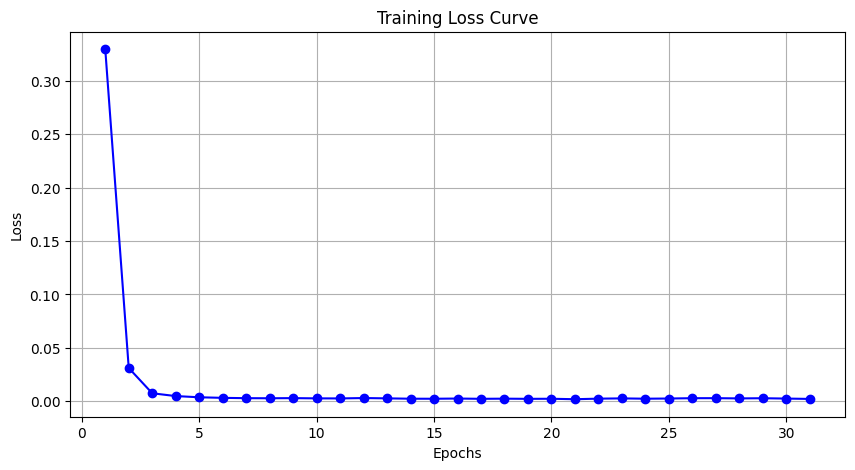

In [5]:
from collections import OrderedDict
from torch.optim.lr_scheduler import CyclicLR

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = UNet().to(device)

criterion = nn.MSELoss()
optimizer = optim.AdamW(model.parameters(), lr=0.0001, weight_decay=1e-5)
scheduler = CyclicLR(optimizer, base_lr=1e-6, max_lr=1e-3, step_size_up=2000, mode='triangular')

# Early stopping parameters
patience = 10
best_loss = float('inf')
trigger_times = 0

num_epochs = 50
train_losses = []

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    for data in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
        inputs = data.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, inputs)
        loss.backward()
        optimizer.step()
        scheduler.step()
        train_loss += loss.item() * inputs.size(0)

    train_loss = train_loss / len(train_loader.dataset)
    train_losses.append(train_loss)
    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {train_loss:.4f}")

    # Early stopping
    if train_loss < best_loss:
        best_loss = train_loss
        trigger_times = 0
    else:
        trigger_times += 1
        if trigger_times >= patience:
            print("Early stopping!")
            break

# Plotting the training loss curve
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_losses) + 1), train_losses, marker='o', linestyle='-', color='b')
plt.title('Training Loss Curve')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)
plt.show()

In [6]:
from PIL import Image
# Compute reconstruction errors on the test set
def compute_reconstruction_error(model, data_loader):
    model.eval()
    errors = []
    with torch.no_grad():
        for data in data_loader:
            inputs = data.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, inputs)
            errors.extend(loss.cpu().numpy().flatten())
    return errors

# Compute reconstruction errors on the test set
test_errors = compute_reconstruction_error(model, test_loader)

# Assuming ground truth labels for anomalies (0 for normal, 1 for anomaly)
# For this example, we will create a dummy ground truth labels array.
# Replace this with actual labels if available.
test_labels = np.zeros(len(test_errors))
# Mark some frames as anomalous for demonstration purposes
test_labels[len(test_labels) // 2:] = 1

# Calculate ROC-AUC
roc_auc = roc_auc_score(test_labels, test_errors)
print(f"ROC-AUC: {roc_auc:.4f}")

# Calculate EER
fpr, tpr, thresholds = roc_curve(test_labels, test_errors)
fnr = 1 - tpr
eer_threshold = thresholds[np.nanargmin(np.absolute(fnr - fpr))]
eer = fpr[np.nanargmin(np.absolute(fnr - fpr))]
print(f"EER: {eer:.4f}")

Error loading image /content/UCSD_Anomaly/UCSD_Anomaly_Dataset/UCSD_Anomaly_Dataset.v1p2/UCSDped1/Test/Test017/142.tif: -2
ROC-AUC: 0.7253
EER: 0.3393
